# SEHAT: eksperimen hybrid retraining aktual

Perbandingan A Shimmer-only, B hybrid, C hybrid berbobot domain/subjek/rekaman,
dan D SEHAT-only. Model Extra Trees tetap 35 trees, depth8, min leaf4, seed42.
Evaluasi **Leave-One-SEHAT-Subject-Out**, prediksi mean per recording, tanpa
personal z-score dan tanpa tuning test. Raw CSV, notebook referensi, dan firmware
tetap utuh. Semua artefak baru berada di `hybrid_retraining_results`.

Notebook utama referensi: `TRAIN_SEHAT_revisi copy.ipynb`; nama `copy(1)` tidak
tersedia. Implementasi dapat ditinjau pada `hybrid_retraining.py`. Parameter QC
ditentukan sebelum model fitting; hasil terpilih tetap studi eksploratif.


In [1]:
from pathlib import Path
import os, sys
PROJECT_ROOT = Path('D:\\ima\\SEM7\\DESPRO 2\\ML')
assert PROJECT_ROOT.is_dir()
sys.path.insert(0, str(PROJECT_ROOT))
from IPython.display import display, Image, Markdown
import pandas as pd
import hybrid_retraining as h
config = h.Config(project_root=str(PROJECT_ROOT))
print("Python:", sys.executable)
print("Project root:", PROJECT_ROOT)
display(pd.Series(h.asdict(config), name="fixed_configuration"))

Python: c:\Users\April\AppData\Local\Programs\Python\Python312\python.exe
Project root: D:\ima\SEM7\DESPRO 2\ML


project_root                    D:\ima\SEM7\DESPRO 2\ML
output_name                   hybrid_retraining_results
fs                                                 51.2
window_sec                                         30.0
overlap                                             0.5
max_gap_sec                                        0.25
max_gsr_missing_fraction                           0.05
max_ppg_bad_fraction                               0.05
gsr_cutoff_hz                                       1.0
gsr_filter_order                                      2
severe_motion_dps                                 100.0
max_severe_motion_fraction                          0.2
max_rr_rejected_fraction                            0.3
ppg_hampel_mad                                      8.0
ppg_hampel_window_sec                              0.25
ppg_min_spike_dc_fraction                          0.02
n_estimators                                         35
max_depth                                       

## 1. Validasi dataset dan provenance label

Shimmer: empat baris header, calibrated PPG mV dan GSR uS; label exact join
subject + timestamp dari fastingTimes. Tidak mengisi nonfasting dengan nol.
SEHAT: IR counts, GSR uS, metadata internal divalidasi terhadap filename/waktu.
Koreksi S16_F02 mengikuti konfirmasi pengguna, F05 tetap disimpan meski raw F04.
Identitas unik memakai relative path dan timestamp; raw tidak ditulis ulang.


In [2]:
manifest = h.inventory(config)
display(manifest.groupby(["device_source", "subject_id"]).agg(files=("file", "size"), labeled=("label_valid", "sum")))
display(manifest.loc[manifest.metadata_conflict, ["file", "subject_id", "raw_subject_id", "session_id", "raw_session_id", "metadata_issues"]])

               files  subjects  sessions  labeled_records
device_source                                            
SEHAT             15         5        15               15
Shimmer          124        11       124               45
Shimmer CSV: 124 raw + 6 label tables; SEHAT CSV: 15 raw
                              file                                                               metadata_issues  identity_resolved
20261107130818_S16_S16_F02_raw.csv subject_filename=S16;internal=S15 | session_filename=S16_F02;internal=S15_F02               True
20261112060931_S13_S13_F05_raw.csv                                     session_filename=S13_F05;internal=S13_F04               True


files  labeled
device_source subject_id                
SEHAT         S12             2        2
              S13             7        7
              S14             2        2
              S15             2        2
              S16             2        2
Shimmer       S1             45       23
              S10             1        0
              S11             1        0
              S2             46        4
              S3              8        4
              S4             12        8
              S5              5        4
              S6              2        2
              S7              1        0
              S8              2        0
              S9              1        0

,file,subject_id,raw_subject_id,session_id,raw_session_id,metadata_issues
130,20261107130818_S16_S16_F02_raw.csv,S16,S15,S16_F02,S15_F02,subject_filename=S16;internal=S15 | session_fi...
135,20261112060931_S13_S13_F05_raw.csv,S13,S13,S13_F05,S13_F04,session_filename=S13_F05;internal=S13_F04


## 2. Preprocessing sensor dan window penuh

Timestamp breaks membatasi filtering; tidak melakukan sort/dedup diam-diam.
Window 30 detik, overlap50%. GSR gap internal <=.25s saja diperbaiki, raw
missing >5% atau unresolved gap menolak window. Filter GSR lama 1Hz order2
per window dipertahankan. PPG .5Hz baseline, low-pass4/2.5Hz, smoothing.15s,
HeartPy dengan quality flags. MAX30102 memiliki pemeriksaan rail dan spike
relatif terhadap baseline lokal. PPG gagal menjadi lima NaN + availability0.
Gyro dipakai untuk QC/filtering saja. Lihat config dan laporan untuk threshold.

Semua raw recording diaudit; CSV fitur training memuat label valid + QC-pass.
Tabel QC window menyimpan juga kandidat yang ditolak dan rekaman tanpa label.


In [3]:
windows, data, qc, examples = h.extract_datasets(manifest, config, workers=int(os.environ.get("SEHAT_HYBRID_WORKERS", "3")))
display(pd.read_csv(config.out / "quality_control_per_domain.csv"))
display(data.groupby("device_source").agg(subjects=("subject_id", "nunique"), recordings=("recording_id", "nunique"), windows=("window_id", "size"), ppg_available=("ppg_available", "mean")))

Feature extraction: 3 raw files to process; 136 verified caches
[137/139] SEHAT 20261113062805_S13_S13_F06_raw.csv: 19/19 windows, 85s
[138/139] SEHAT 20261113070600_S13_S13_F07_raw.csv: 19/19 windows, 85s
[139/139] SEHAT 20261113073747_S13_S13_F08_raw.csv: 19/19 windows, 85s
Extraction complete in 1.50 minutes; 4326 labeled QC-pass windows


,device_source,files,subjects,sessions,labeled_records,samples,candidate_windows,accepted_windows,rejected_windows,ppg_available_windows,samples_in_accepted_windows,samples_outside_full_windows,gsr_interpolated_samples,window_pass_pct,sample_coverage_pass_pct
0,SEHAT,15,5,15,15,230400,285,279,6,211,225792,0,509,97.894737,98.000000
1,Shimmer,124,11,124,45,10032887,11986,11925,61,1743,9505536,505847,0,99.491073,94.743776


,subjects,recordings,windows,ppg_available
device_source,,,,
SEHAT,5,15,279,0.756272
Shimmer,6,39,4047,0.173462


## 3. Empat eksperimen dengan subjek uji identik

Semua statistik imputasi berasal dari training fold. Tidak menggunakan
personal z-score, metadata predictor, log transform, atau random window split.
C menggunakan bobot hierarki domain -> subjek -> rekaman -> window yang
dihitung ulang dari training. Metrik utama berbasis rekaman; macro subject MAE
juga dilaporkan. R² fold dengan <3 rekaman tidak disajikan sebagai angka stabil.


In [4]:
oof, records, per_subject, summary, best_name = h.evaluate(data, config)
display(summary)
display(per_subject)
display(records[["model", "subject_id", "session_id", "y_true", "y_pred", "absolute_error_hr", "windows"]])

LOSO fold 1: S12, 2 test recordings, 38 identical test windows for A/B/C/D
LOSO fold 2: S13, 7 test recordings, 127 identical test windows for A/B/C/D
LOSO fold 3: S14, 2 test recordings, 38 identical test windows for A/B/C/D
LOSO fold 4: S15, 2 test recordings, 38 identical test windows for A/B/C/D
LOSO fold 5: S16, 2 test recordings, 38 identical test windows for A/B/C/D
              model  n_recordings   MAE_hr  RMSE_hr        R2  target_min_hr  target_max_hr  macro_subject_MAE_hr
     A_Shimmer_only            15 4.688992 5.627618 -1.946692       1.034718       9.629812              5.424750
B_Hybrid_unweighted            15 3.210378 3.610402 -0.212821       1.034718       9.629812              3.322066
  C_Hybrid_weighted            15 2.858798 3.401708 -0.076663       1.034718       9.629812              3.162460
       D_SEHAT_only            15 2.491909 2.947612  0.191600       1.034718       9.629812              2.152245
Selected exploratory model: D_SEHAT_only


,model,n_recordings,MAE_hr,RMSE_hr,R2,target_min_hr,target_max_hr,macro_subject_MAE_hr
0,A_Shimmer_only,15,4.688992,5.627618,-1.946692,1.034718,9.629812,5.424750
1,B_Hybrid_unweighted,15,3.210378,3.610402,-0.212821,1.034718,9.629812,3.322066
2,C_Hybrid_weighted,15,2.858798,3.401708,-0.076663,1.034718,9.629812,3.162460
3,D_SEHAT_only,15,2.491909,2.947612,0.191600,1.034718,9.629812,2.152245


,model,subject_id,n_recordings,MAE_hr,RMSE_hr,R2,target_min_hr,target_max_hr
0,A_Shimmer_only,S12,2,5.775967,6.241691,NaN,1.230339,5.275029
1,A_Shimmer_only,S13,7,3.217476,4.693090,-0.781840,1.300721,9.629812
2,A_Shimmer_only,S14,2,7.203222,7.215399,NaN,1.034718,1.962393
3,A_Shimmer_only,S15,2,5.717656,5.744813,NaN,1.427739,4.480752
4,A_Shimmer_only,S16,2,5.209429,6.034419,NaN,1.371714,6.905173
5,B_Hybrid_unweighted,S12,2,3.647508,3.993335,NaN,1.230339,5.275029
6,B_Hybrid_unweighted,S13,7,2.987000,3.117035,0.213979,1.300721,9.629812
7,B_Hybrid_unweighted,S14,2,3.374601,3.416037,NaN,1.034718,1.962393
8,B_Hybrid_unweighted,S15,2,3.192908,4.020054,NaN,1.427739,4.480752
9,B_Hybrid_unweighted,S16,2,3.408314,4.469900,NaN,1.371714,6.905173


,model,subject_id,session_id,y_true,y_pred,absolute_error_hr,windows
0,A_Shimmer_only,S12,S12_F01,5.275029,8.685219,3.410190,19
1,A_Shimmer_only,S12,S12_F02,1.230339,9.372084,8.141745,19
2,A_Shimmer_only,S13,S13_F01,3.761936,7.886474,4.124538,19
3,A_Shimmer_only,S13,S13_F02,1.300721,9.543467,8.242746,19
4,A_Shimmer_only,S13,S13_F03,1.632967,9.881969,8.249002,13
5,A_Shimmer_only,S13,S13_F05,9.425423,9.737476,0.312053,19
6,A_Shimmer_only,S13,S13_F06,8.468187,9.388515,0.920328,19
7,A_Shimmer_only,S13,S13_F07,9.100093,9.479640,0.379547,19
8,A_Shimmer_only,S13,S13_F08,9.629812,9.335697,0.294115,19
9,A_Shimmer_only,S14,S14_F01,1.962393,8.746588,6.784195,19


## 4. Grafik sinyal, distribusi fitur, prediksi dan residual

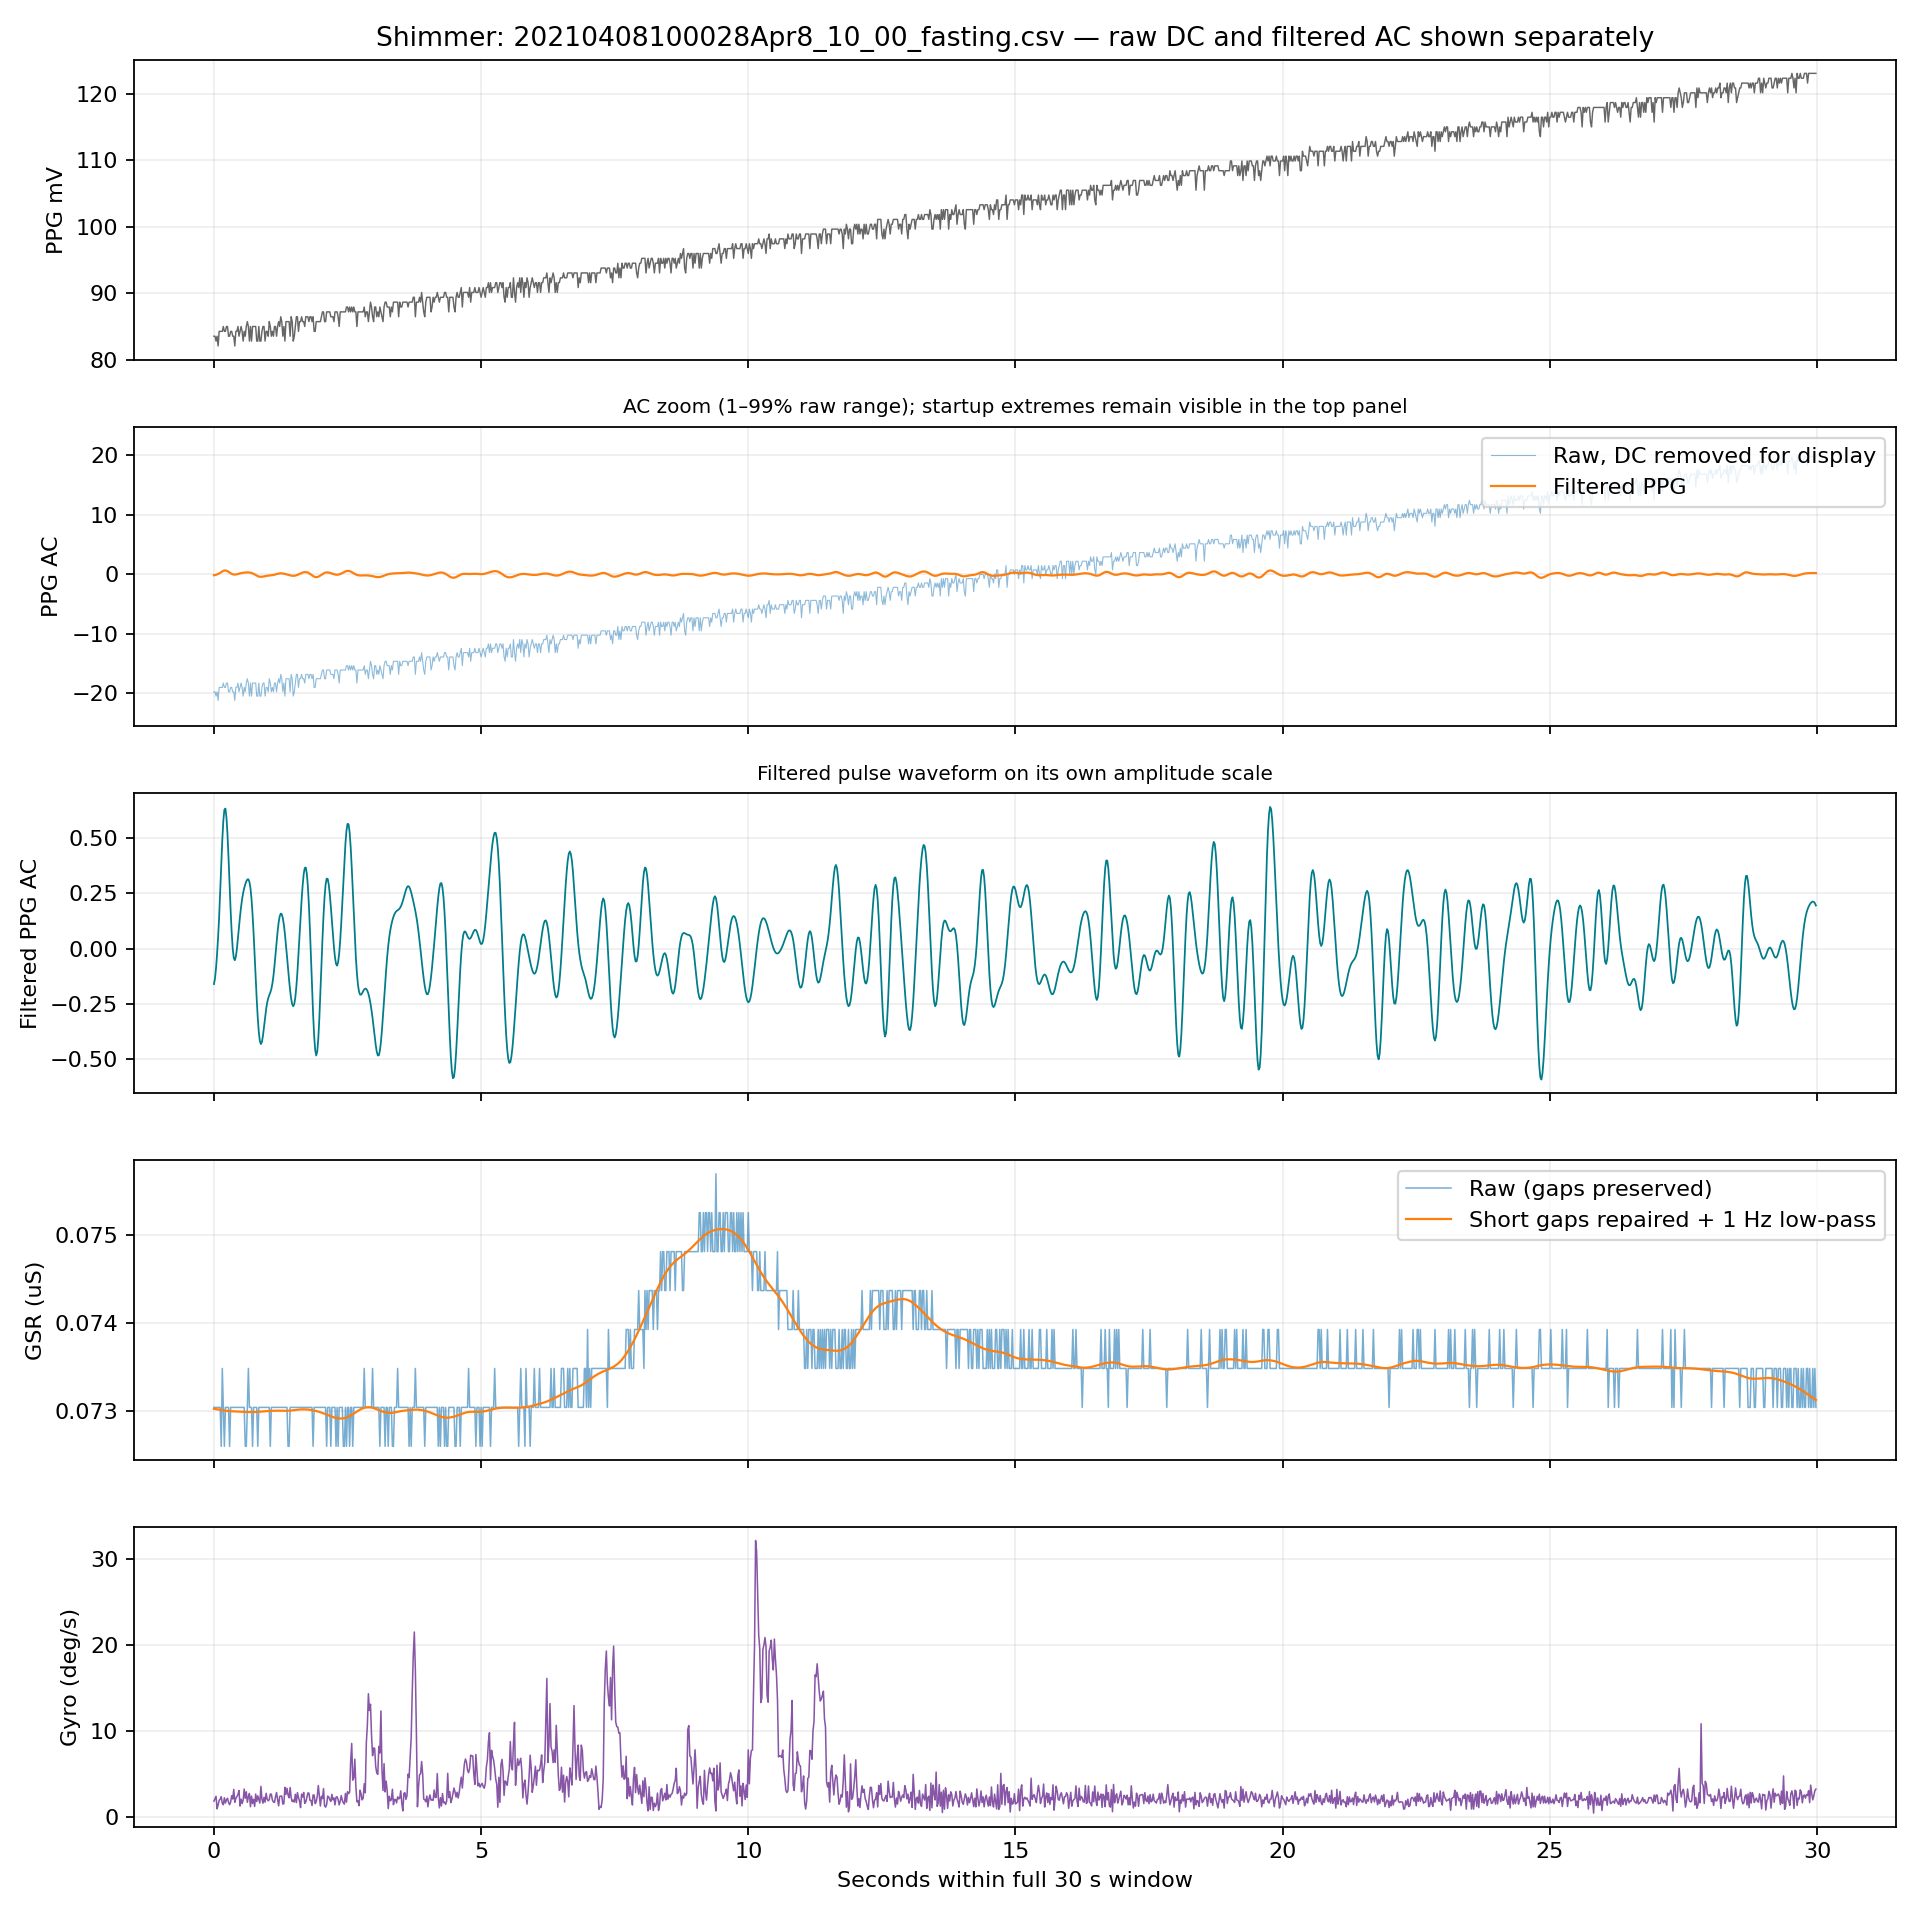

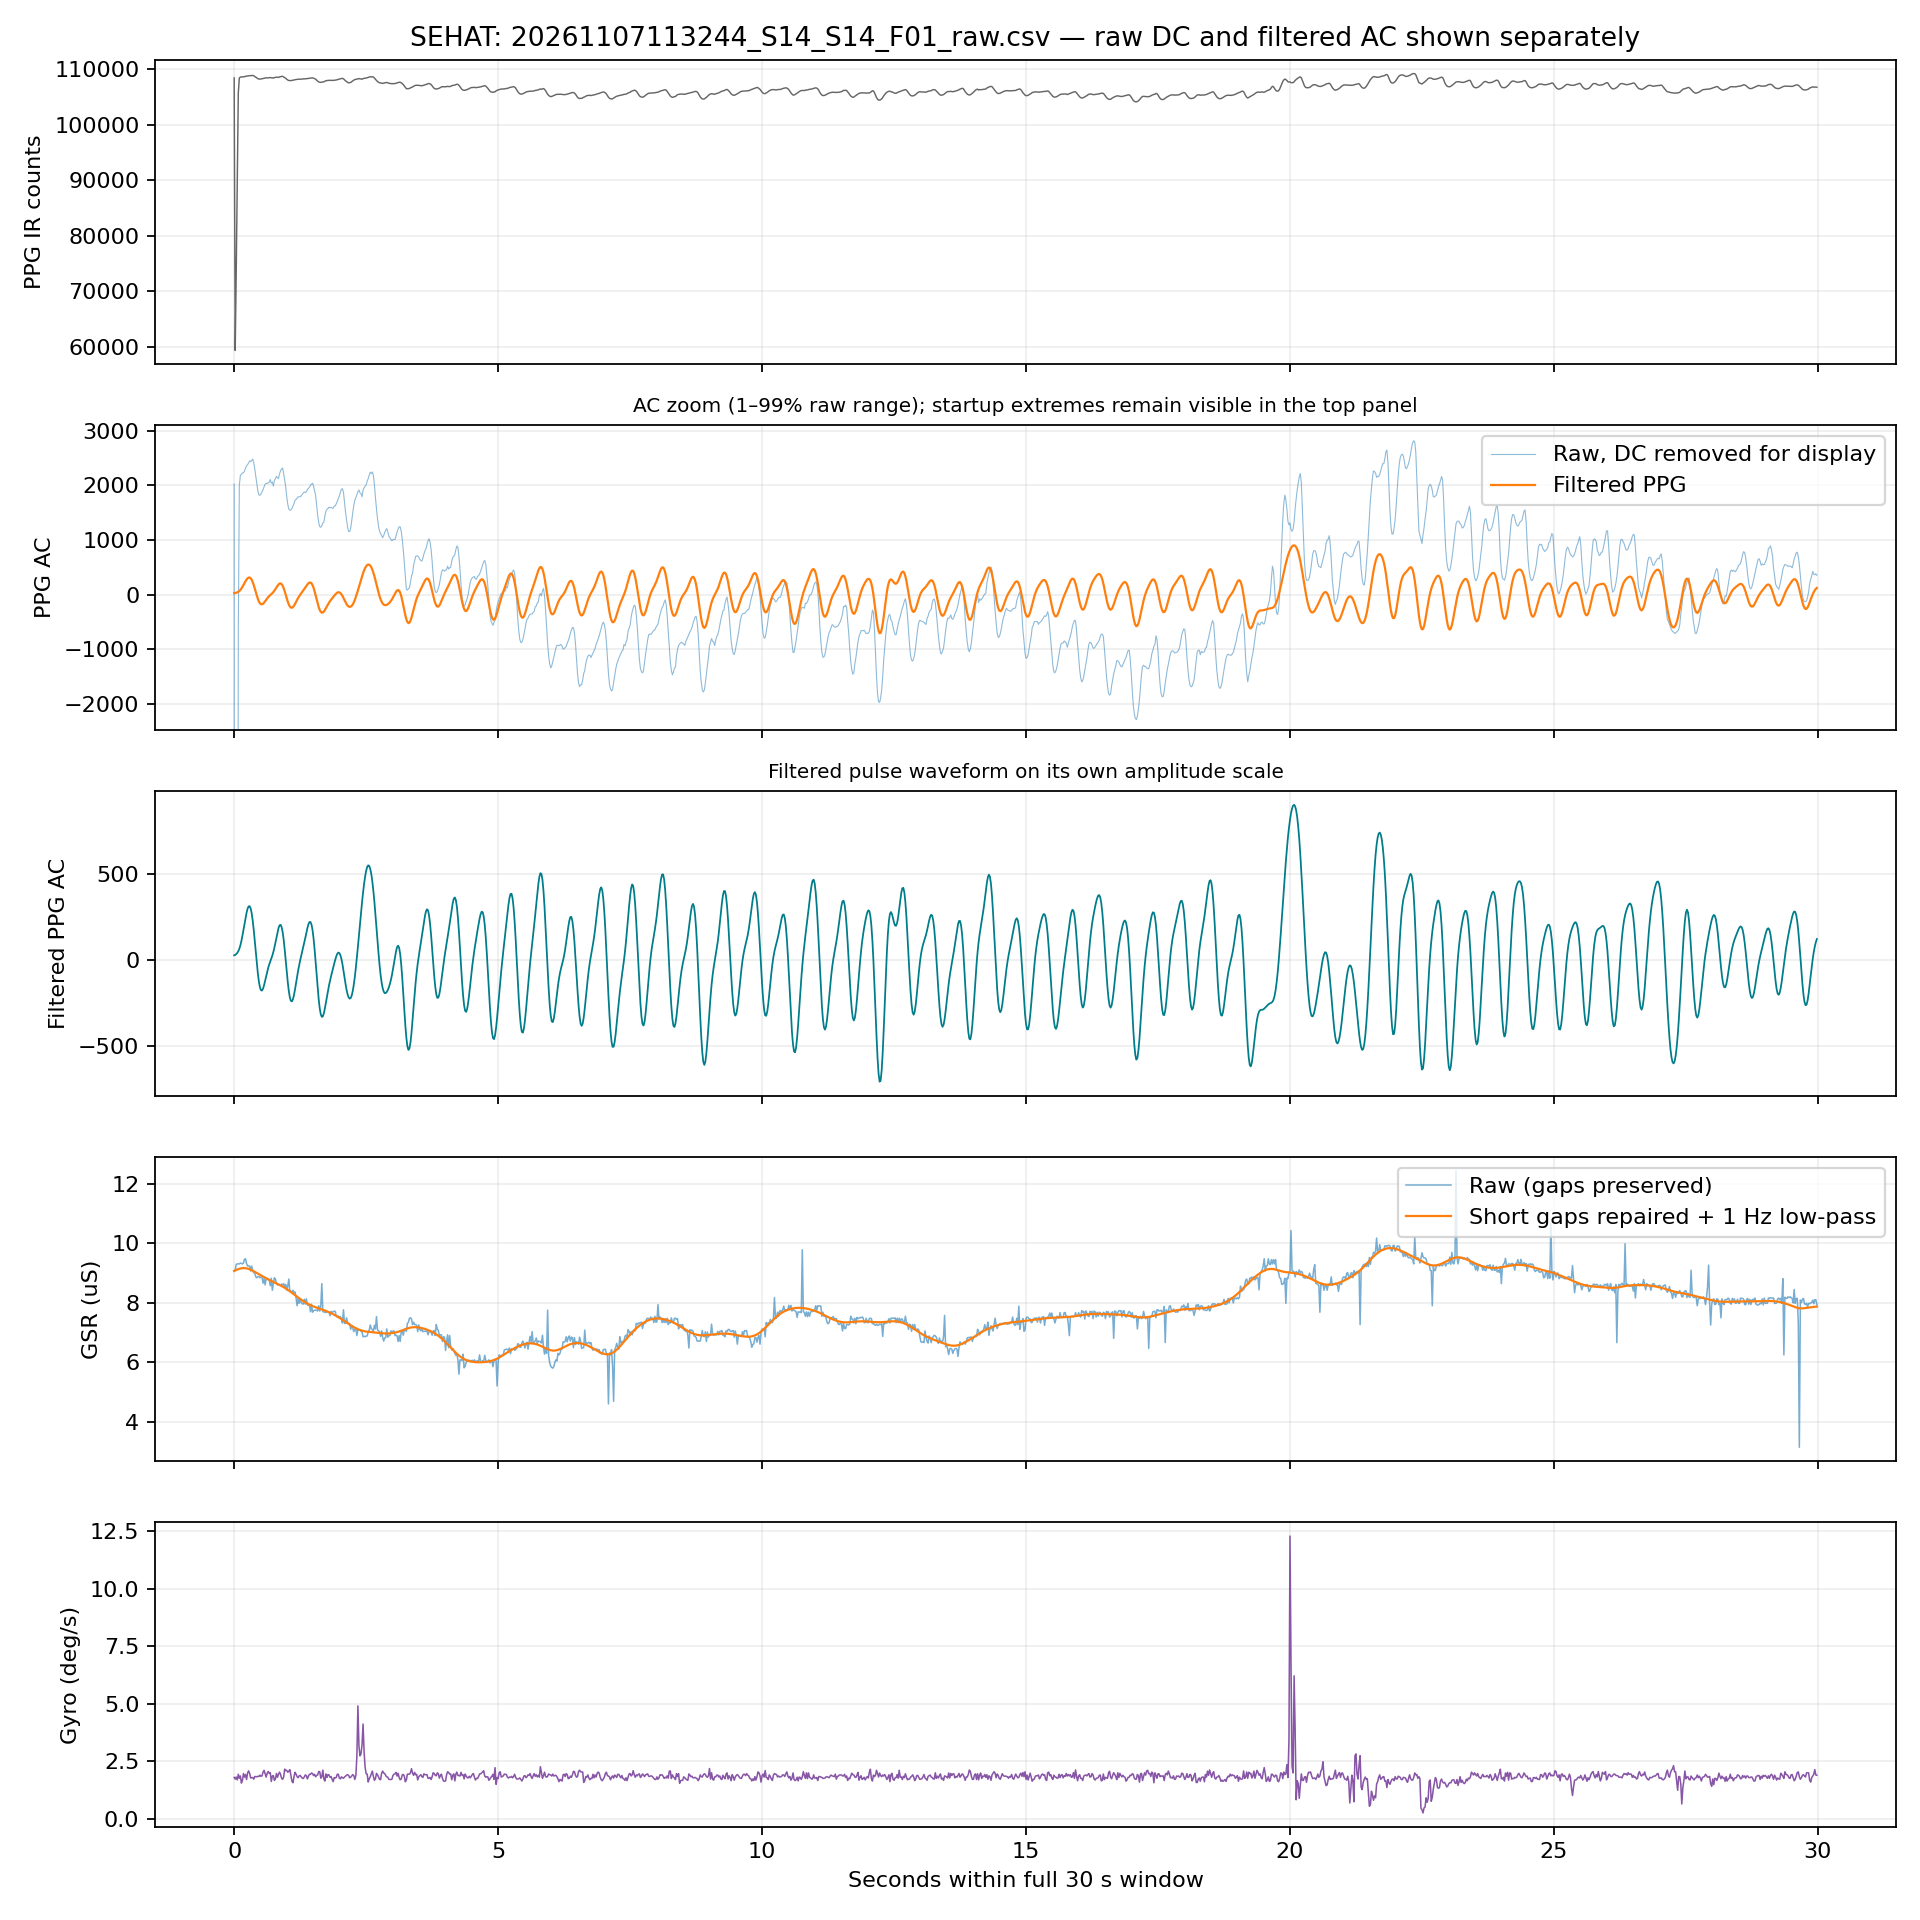

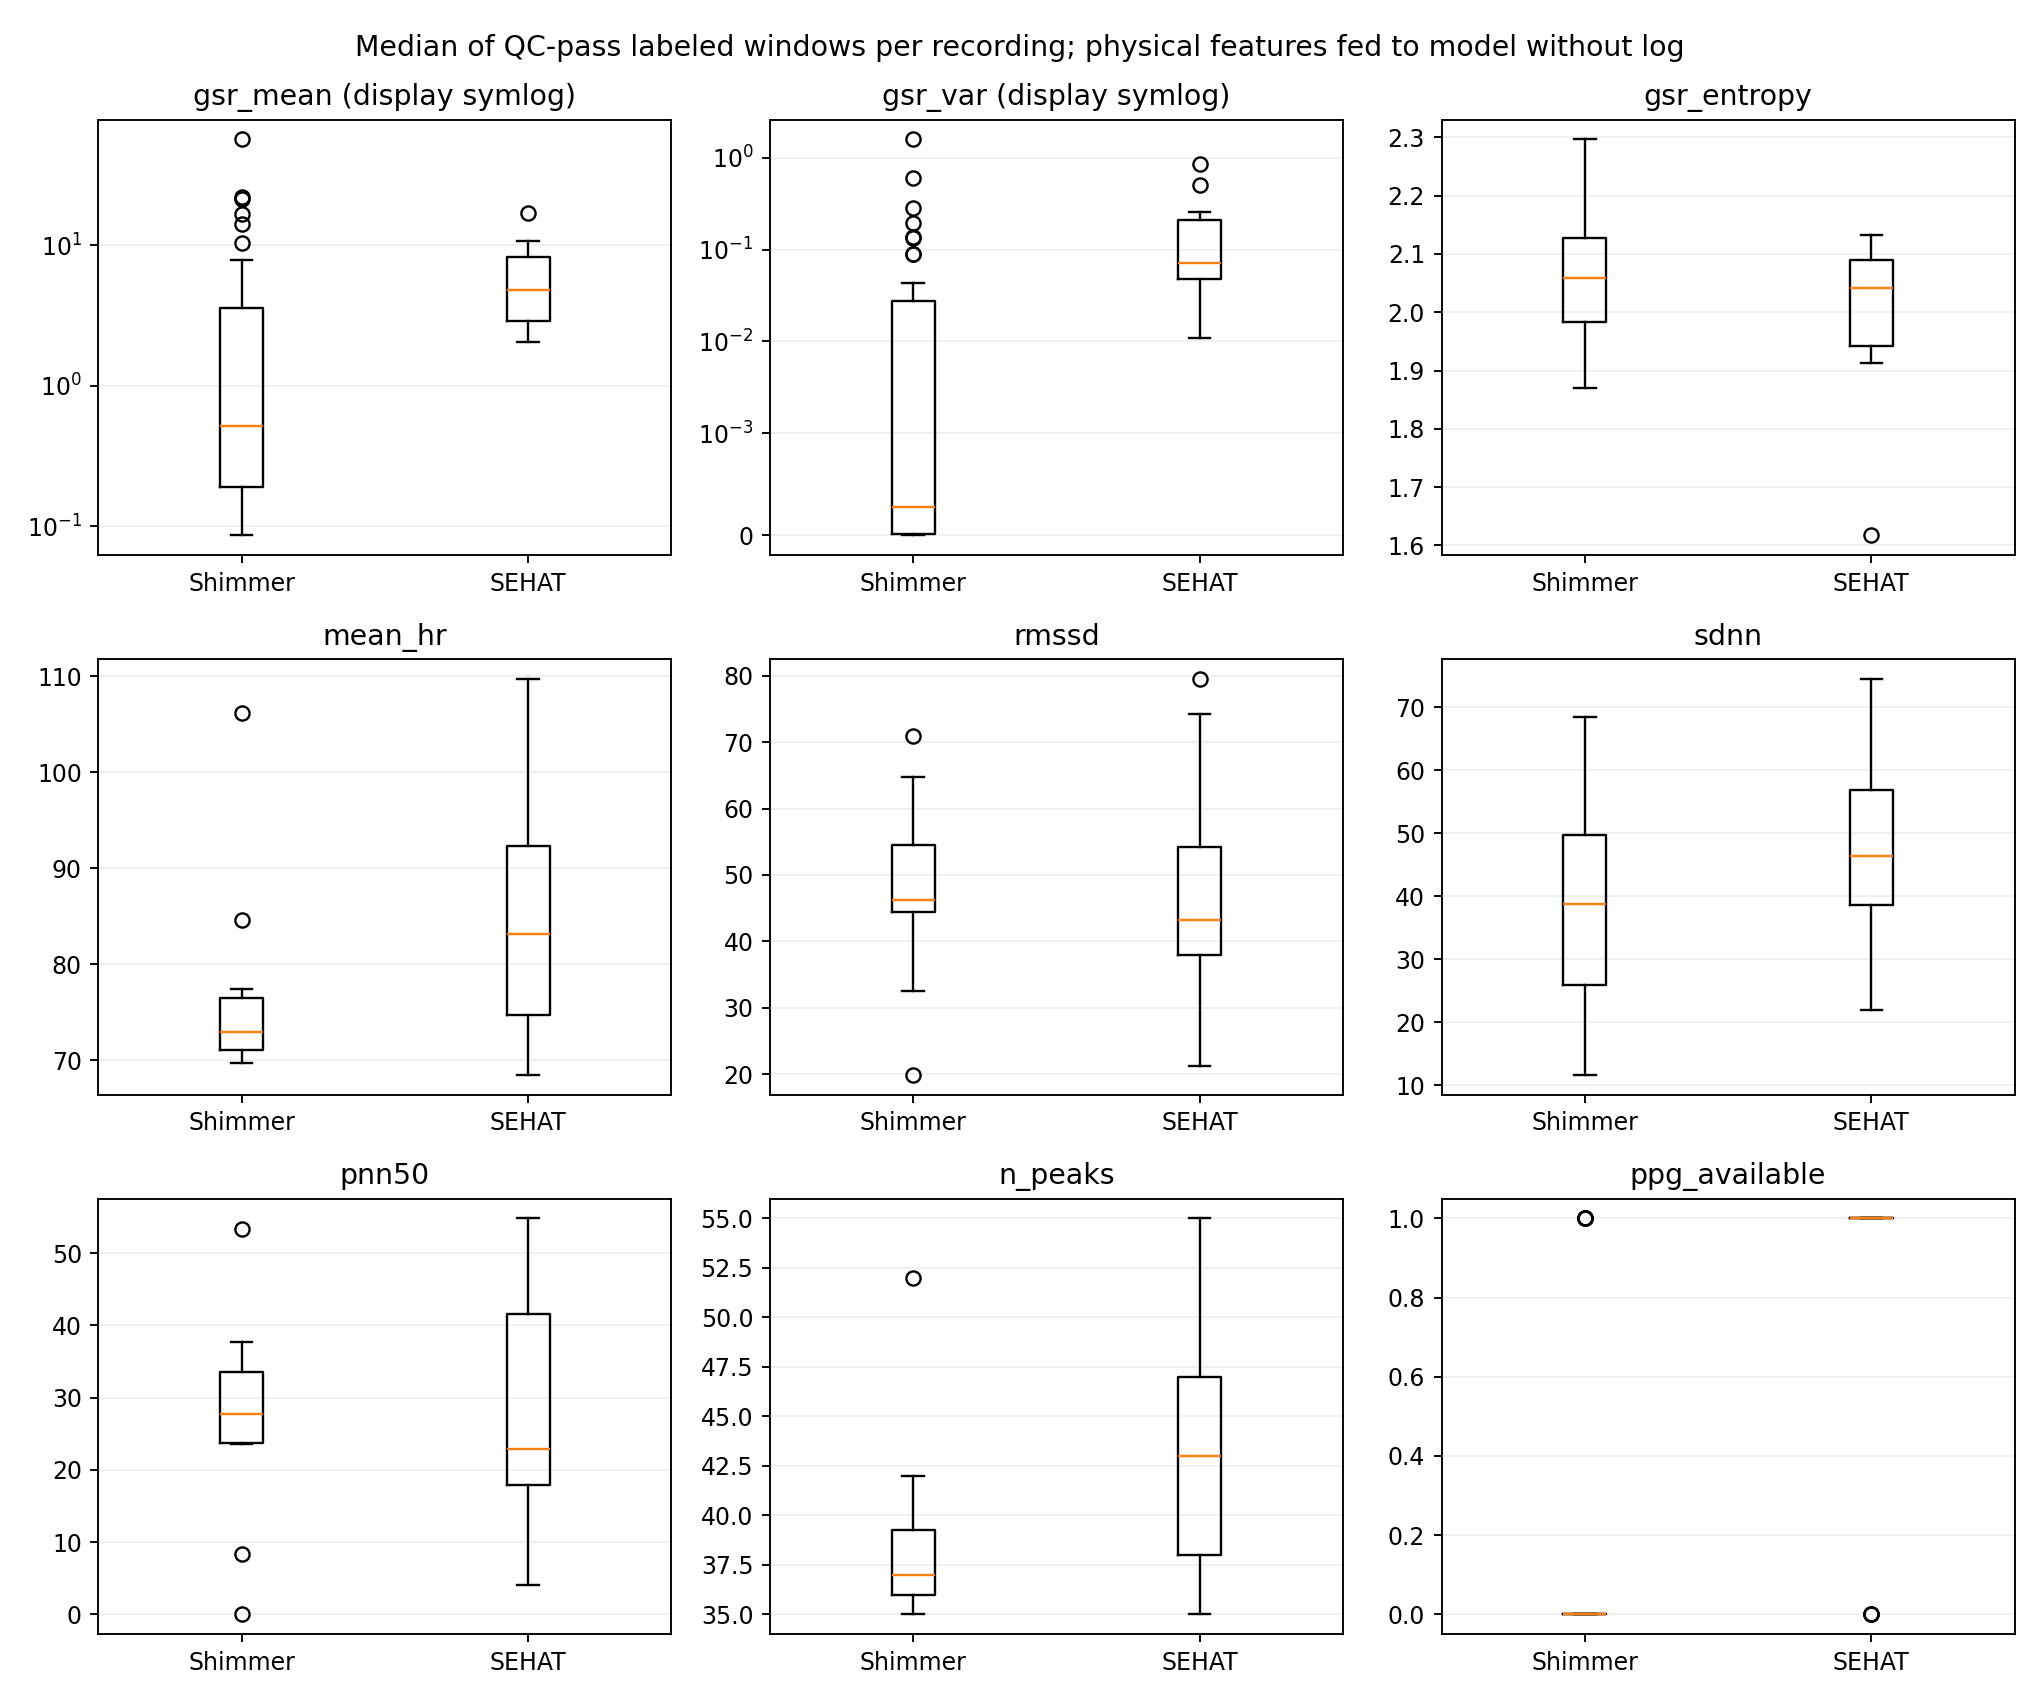

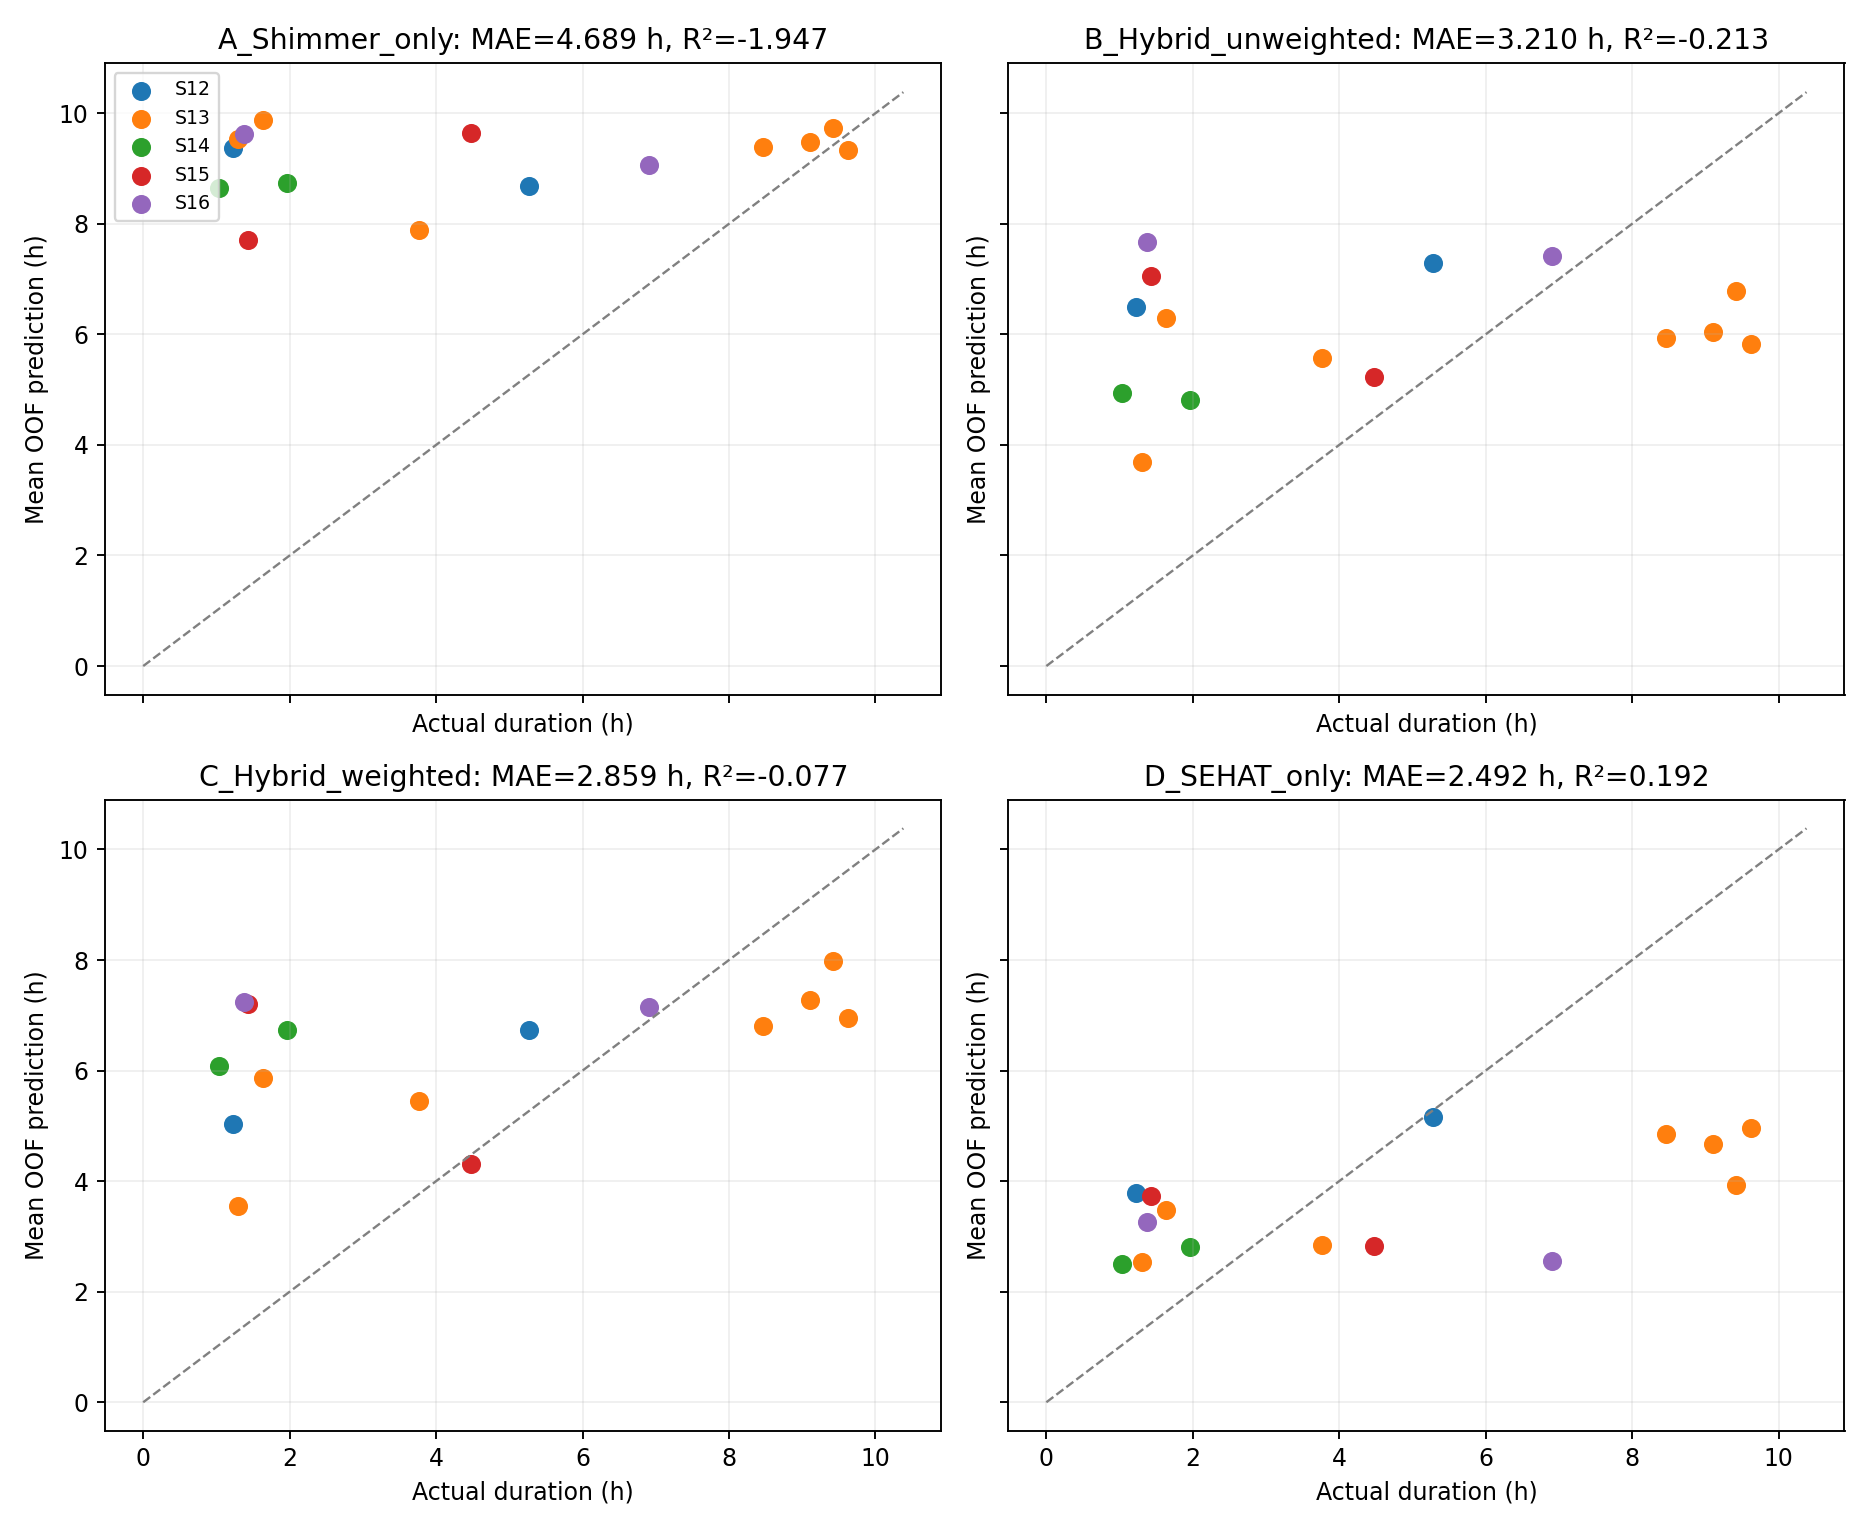

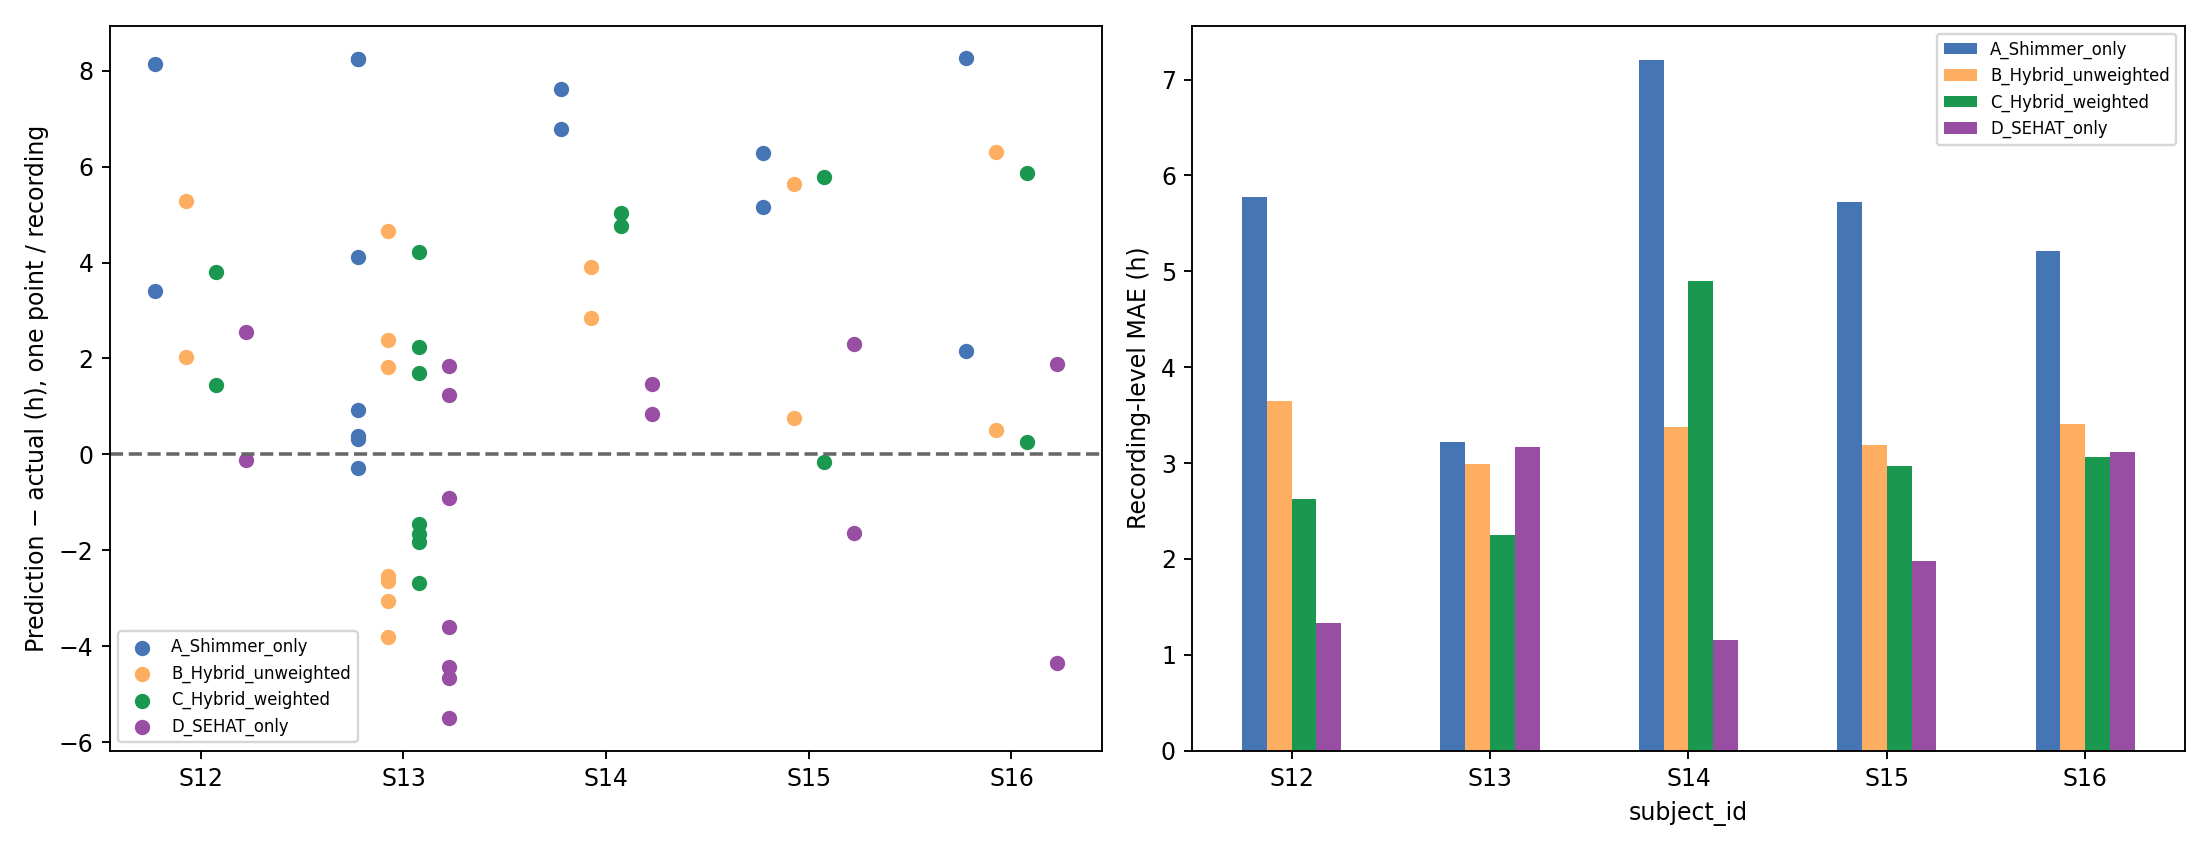

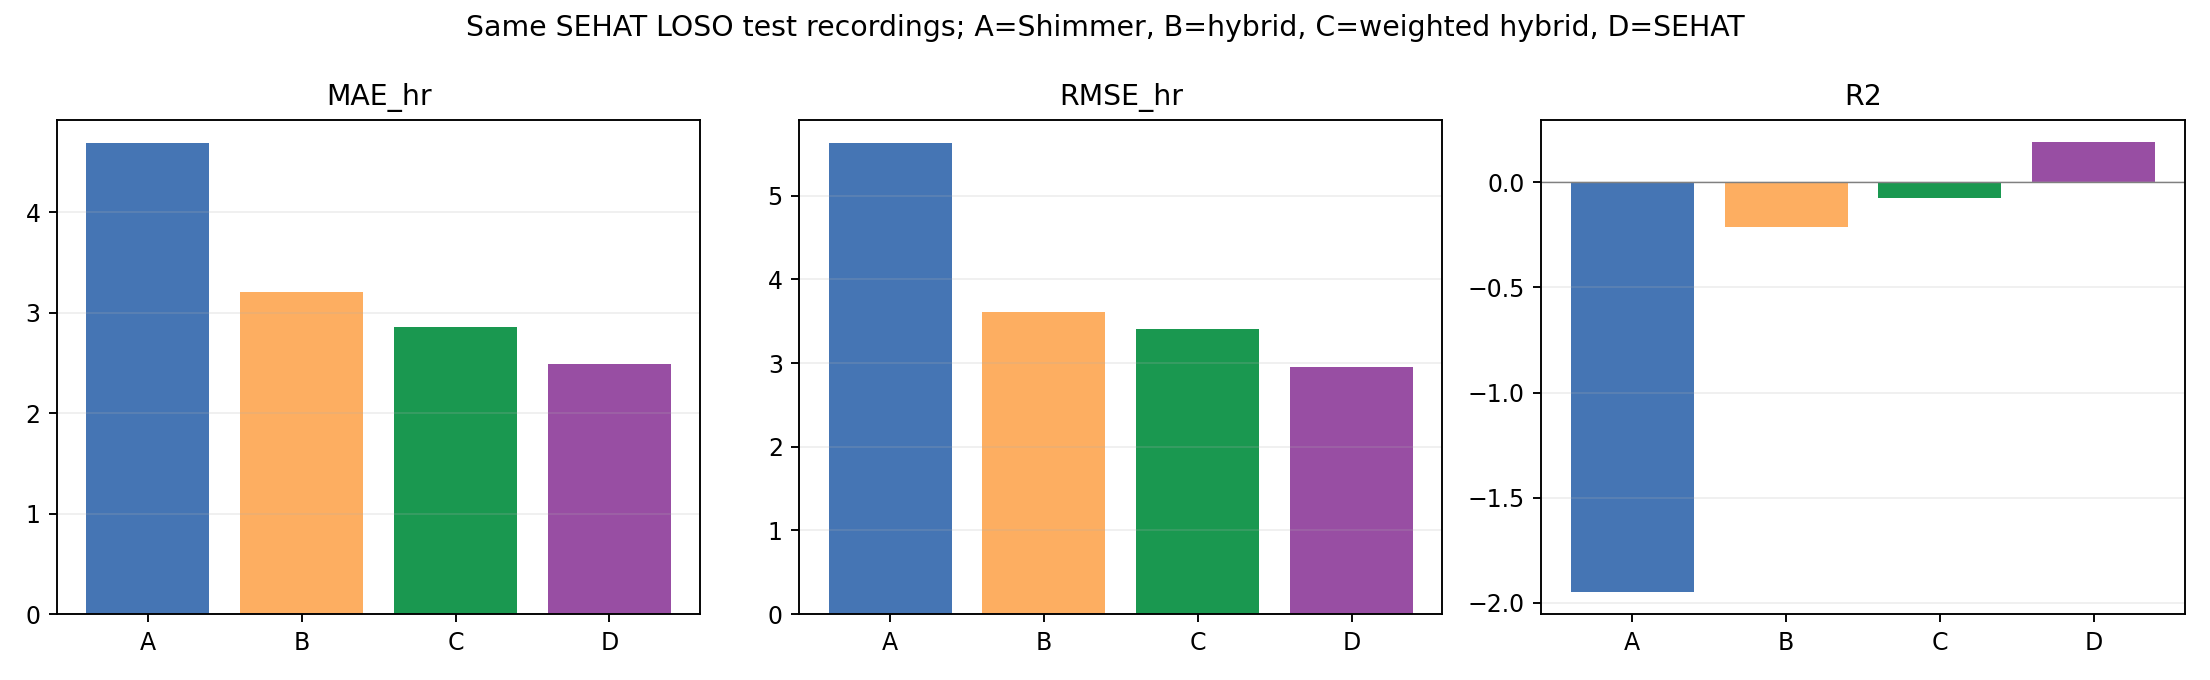

In [5]:
h.plot_signals(examples, config)
record_features = h.plot_evaluation(data, records, per_subject, summary, config)
for name in ["signals_shimmer", "signals_sehat", "feature_distributions", "actual_vs_predicted", "errors_per_subject", "model_comparison"]:
    display(Image(filename=str(config.out / "figures" / (name + ".png"))))

## 5. Sensitivitas preprocessing tanpa pemilihan dari skor test

PPG source50Hz sebelum interpolasi firmware tidak tersimpan. Rekonstruksi50Hz
dan roundtrip51.2Hz hanya mengukur sensitivitas tambahan interpolasi, bukan
membuktikan akurasi HRV asli. Kontrol sintetis memakai beat times diketahui.
GSR1Hz dibanding2Hz untuk melihat perubahan mean/variance; filter tidak dipilih
dari skor test. Tidak ada klaim kesetaraan fisiologis kedua domain.


In [6]:
sensitivity, gsr_sensitivity = h.sensor_sensitivity(manifest, windows, config)
display(sensitivity)
display(gsr_sensitivity[["variance_ratio_1hz_raw", "variance_ratio_2hz_raw", "absolute_mean_shift_1hz"]].describe())
display(pd.read_csv(config.out / "audit/ppg_synthetic_known_beats.csv"))

c:\Users\April\AppData\Local\Programs\Python\Python312\Lib\site-packages\heartpy\datautils.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


,method,feature,paired_windows,both_valid_windows,availability_disagreements,median_absolute_difference,max_absolute_difference
0,reconstructed_50,mean_hr,285,214,6,0.016667,1.974506
1,reconstructed_50,rmssd,285,214,6,1.303411,11.894751
2,reconstructed_50,sdnn,285,214,6,0.600526,21.151603
3,reconstructed_50,pnn50,285,214,6,2.857143,17.069597
4,reconstructed_50,n_peaks,285,214,6,1.000000,23.000000
5,roundtrip_51.2,mean_hr,285,214,3,0.007872,0.906421
6,roundtrip_51.2,rmssd,285,214,3,1.296711,16.878473
7,roundtrip_51.2,sdnn,285,214,3,0.471694,11.545635
8,roundtrip_51.2,pnn50,285,214,3,2.762515,14.634146
9,roundtrip_51.2,n_peaks,285,214,3,0.000000,2.000000


,variance_ratio_1hz_raw,variance_ratio_2hz_raw,absolute_mean_shift_1hz
count,285.000000,285.000000,285.000000
mean,0.621465,0.659340,0.000520
std,0.273092,0.254241,0.000730
min,0.028854,0.073317,0.000002
25%,0.411382,0.466617,0.000126
50%,0.690431,0.714935,0.000258
75%,0.854564,0.882439,0.000631
max,0.994231,0.994784,0.006198


,method,rhythm,sample_phase_sec,start_sec,available,true_mean_hr,true_rmssd,true_sdnn,true_pnn50,true_n_peaks,mean_hr,rmssd,sdnn,pnn50,n_peaks,absolute_error_mean_hr,absolute_error_rmssd,absolute_error_sdnn,absolute_error_pnn50,absolute_error_n_peaks
0,known_native_50,constant_RR,0.000000,0,True,75.000000,4.440653e-13,4.559301e-13,0.000000,37,75.000000,0.000000,0.000000,0.000000,33,2.842171e-14,4.440653e-13,4.559301e-13,0.000000,4
1,known_native_50,constant_RR,0.000000,15,False,75.000000,6.525312e-13,1.742285e-12,0.000000,38,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,38
2,known_native_50,constant_RR,0.000000,30,True,75.000000,5.873820e-13,5.793900e-13,0.000000,38,75.068475,4.500000,4.378378,0.000000,38,6.847462e-02,4.500000e+00,4.378378e+00,0.000000,0
3,known_native_50,constant_RR,0.000000,45,False,75.000000,0.000000e+00,1.136868e-13,0.000000,37,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,37
4,linear_50_to_51.2,constant_RR,0.000000,0,True,75.000000,4.440653e-13,4.559301e-13,0.000000,37,74.995850,1.298372,0.897206,0.000000,37,4.150161e-03,1.298372e+00,8.972063e-01,0.000000,0
5,linear_50_to_51.2,constant_RR,0.000000,15,True,75.000000,6.525312e-13,1.742285e-12,0.000000,38,74.991449,1.258327,0.803956,0.000000,38,8.550545e-03,1.258327e+00,8.039565e-01,0.000000,0
6,linear_50_to_51.2,constant_RR,0.000000,30,True,75.000000,5.873820e-13,5.793900e-13,0.000000,38,75.056181,4.600450,4.267950,0.000000,38,5.618120e-02,4.600450e+00,4.267950e+00,0.000000,0
7,linear_50_to_51.2,constant_RR,0.000000,45,True,75.000000,0.000000e+00,1.136868e-13,0.000000,37,75.007651,1.558423,1.003636,0.000000,37,7.650520e-03,1.558423e+00,1.003636e+00,0.000000,0
8,known_native_50,constant_RR,0.006667,0,False,75.000000,4.440653e-13,4.559301e-13,0.000000,37,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,37
9,known_native_50,constant_RR,0.006667,15,False,75.000000,6.525312e-13,1.742285e-12,0.000000,38,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,38


## 6. Baseline durasi konstan dan ketidakpastian tingkat subjek

Bootstrap memperlakukan subjek sebagai cluster. Dengan lima subjek saja,
interval bersifat deskriptif. Memilih pemenang pada LOSO yang sama memberi
hasil eksploratif; konfirmasi memerlukan cohort baru atau validasi tersarang.


In [7]:
uncertainty = h.auxiliary_evaluation(data, records, per_subject, config)
display(pd.read_csv(config.out / "audit/constant_baseline_metrics.csv"))
display(uncertainty)

,model,n_recordings,MAE_hr,RMSE_hr,R2,target_min_hr,target_max_hr
0,constant_SEHAT_train_record_mean,15,3.232587,3.845313,-0.375780,1.034718,9.629812
1,constant_SEHAT_train_record_median,15,3.397475,4.292113,-0.714067,1.034718,9.629812
2,constant_Shimmer_record_mean,15,5.040095,5.996706,-2.345885,1.034718,9.629812
3,constant_Shimmer_record_median,15,5.318145,6.247426,-2.631515,1.034718,9.629812


,model,contrast,subjects,delta_macro_MAE_hr,lower95,upper95,subjects_improved,bootstrap_replicates,caution
0,B_Hybrid_unweighted,"model minus A; macro subject MAE, hours",5,-2.102684,-3.148556,-1.003458,5,10000,"exploratory five-subject bootstrap, not confir..."
1,C_Hybrid_weighted,"model minus A; macro subject MAE, hours",5,-2.262290,-2.826651,-1.558454,5,10000,"exploratory five-subject bootstrap, not confir..."
2,D_SEHAT_only,"model minus A; macro subject MAE, hours",5,-3.272505,-4.942386,-1.333622,5,10000,"exploratory five-subject bootstrap, not confir..."


## 7. Validasi integritas, model Python, dan laporan akhir

Pemeriksaan meliputi subjek/rekaman disjoint, kesamaan test empat model,
frozen training medians, bobot, partial-window policy, metadata provenance,
roundtrip serialisasi model, perhitungan ulang metrik, dan hash seluruh raw.
Model final direfit sesudah evaluasi; metrik yang dilaporkan tetap OOF.
Firmware dan model TinyML .h tidak diekspor/diubah.


In [8]:
validation = h.validate_results(manifest, windows, data, records, summary, config)
counts = h.write_report(manifest, windows, data, qc, summary, per_subject, best_name, sensitivity, gsr_sensitivity, uncertainty, config)
display(counts)
display(summary)
print("Model terpilih (eksploratif):", best_name)
print("Pipeline + preprocessing:", config.out / "models/best_model_pipeline.joblib")
print("Laporan:", config.out / "EXPERIMENT_REPORT.md")
display(Markdown((config.out / "EXPERIMENT_REPORT.md").read_text(encoding="utf-8")))

Validation passed: {'passed': True, 'raw_files_verified': 139, 'model_folds_verified': 20, 'same_test_recordings_per_model': 15, 'feature_count': 9, 'tests': ['full windows only', 'no train/test subject or recording leakage', 'identical A/B/C/D test rows', 'frozen train-only imputation', 'hierarchical weight mass', 'gap boundaries and long gap retention', 'metadata override provenance', 'F05 retained', 'serialized model prediction roundtrip', 'metrics recomputed from CSV', 'raw SHA256 unchanged']}
Saved report: D:\ima\SEM7\DESPRO 2\ML\hybrid_retraining_results\EXPERIMENT_REPORT.md


,device_source,files,subjects,sessions,labeled_records,samples,candidate_windows,accepted_windows,rejected_windows,ppg_available_windows,samples_in_accepted_windows,samples_outside_full_windows,gsr_interpolated_samples,window_pass_pct,sample_coverage_pass_pct,usable_recordings,usable_subjects,usable_windows
0,SEHAT,15,5,15,15,230400,285,279,6,211,225792,0,509,97.894737,98.000000,15,5,279
1,Shimmer,124,11,124,45,10032887,11986,11925,61,1743,9505536,505847,0,99.491073,94.743776,39,6,4047


,model,n_recordings,MAE_hr,RMSE_hr,R2,target_min_hr,target_max_hr,macro_subject_MAE_hr
0,A_Shimmer_only,15,4.688992,5.627618,-1.946692,1.034718,9.629812,5.424750
1,B_Hybrid_unweighted,15,3.210378,3.610402,-0.212821,1.034718,9.629812,3.322066
2,C_Hybrid_weighted,15,2.858798,3.401708,-0.076663,1.034718,9.629812,3.162460
3,D_SEHAT_only,15,2.491909,2.947612,0.191600,1.034718,9.629812,2.152245


Model terpilih (eksploratif): D_SEHAT_only
Pipeline + preprocessing: D:\ima\SEM7\DESPRO 2\ML\hybrid_retraining_results\models\best_model_pipeline.joblib
Laporan: D:\ima\SEM7\DESPRO 2\ML\hybrid_retraining_results\EXPERIMENT_REPORT.md


# Eksperimen hybrid SEHAT — hasil aktual

Eksperimen offline menggunakan ExtraTreesRegressor (35 trees, depth 8, min leaf 4, seed 42), tanpa tuning. Evaluasi Leave-One-SEHAT-Subject-Out: semua sesi subjek uji dikeluarkan dari training. Empat model memakai window uji yang identik. Prediksi window dirata-ratakan per rekaman; metrik utama memberi setiap rekaman bobot sama.

## Data dan kualitas

device_source  files  subjects  sessions  labeled_records  samples  candidate_windows  accepted_windows  rejected_windows  ppg_available_windows  samples_in_accepted_windows  samples_outside_full_windows  gsr_interpolated_samples  window_pass_pct  sample_coverage_pass_pct  usable_recordings  usable_subjects  usable_windows
        SEHAT     15         5        15               15   230400                285               279                 6                    211                       225792                             0                       509        97.894737                 98.000000                 15                5             279
      Shimmer    124        11       124               45 10032887              11986             11925                61                   1743                      9505536                        505847                         0        99.491073                 94.743776                 39                6            4047

Jumlah CSV Shimmer mentah=124, tabel label fastingTimes=6 (total 130); SEHAT mentah=12. Angka tersebut diverifikasi pada manifest. QC dilakukan terhadap seluruh raw recording, termasuk Shimmer tanpa label; hanya label eksplisit yang valid masuk regresi.

Persentase lolos dihitung dari kandidat window **penuh** di setiap continuous run. Sampel di tail/run pendek tidak diperlakukan sebagai window parsial; jumlahnya ada pada `samples_outside_full_windows`. Sample coverage menghitung gabungan indeks sampel window lolos, sehingga overlap tidak dihitung dua kali. Lolos kualitas sinyal tidak otomatis berarti memiliki label regresi.

### Konflik metadata

- `20261107130818_S16_S16_F02_raw.csv`: raw menyebut S15/S15_F02. Pengguna mengonfirmasi subjek sebenarnya **S16**; manifest memakai S16/S16_F02 dan mempertahankan raw_subject_id/raw_session_id serta alasan koreksi.
- `20261112060931_S13_S13_F05_raw.csv`: raw menyebut session S13_F04. Rekaman **tetap dipakai** sebagai F05 dengan recording_id dari relative path dan timestamp; raw metadata tidak diubah.
- Label Shimmer digabung exact pada (subject_id, RecordingTime), bukan timestamp lintas subjek atau nearest matching. Nonfasting tanpa label tidak diisi nol. Lihat `audit/excluded_recordings.csv` untuk seluruh pengecualian.

## Preprocessing dan fitur

Loader Shimmer mempertahankan header empat baris, PPG calibrated mV, GSR calibrated uS, serta device Timestamp_CAL. Timestamp sistem yang stuck bukan alasan otomatis menghapus file bila device timestamp valid. Loader SEHAT membaca IR counts, GSR uS, elapsed_us, dan gyro deg/s. Tidak ada penyamaan amplitudo PPG raw antarperangkat.

Timestamp tidak diurutkan ulang atau dideduplikasi diam-diam: nilai nonfinite, nonpositive dt, dan penyimpangan dt >50% periode nominal memisahkan continuous run. FS median dan FS berdasarkan elapsed dicatat per file. Timestamp SEHAT adalah grid buatan firmware: fs nominal tepat bukan bukti clock MAX30102/FIFO atau waktu serial benar-benar bebas jitter.

Beberapa file Shimmer memiliki sampling/timestamp tidak sesuai konfigurasi nominal; lihat `sampling_rate_flag`, `short_runs_not_filtered`, dan `samples_outside_full_windows`. Run yang lebih pendek dari 1536 sampel kontinu tidak difilter dan tidak menghasilkan window. Tidak mempercepat sinyal 0.2/10.24Hz seolah-olah 51.2Hz.

GSR: NaN/Inf dicatat sebelum perbaikan; nilai <=0 ditandai invalid. Hanya gap internal <=0.25 s yang diinterpolasi, tanpa extrapolasi tepi atau melintasi putus timestamp. Window ditolak bila >5% raw missing, masih ada gap, >5% nonpositive, atau >5% ADC rail. Butterworth order 2 low-pass 1 Hz per window dipertahankan dari notebook lama; varians ddof=0, entropy histogram 10 bin log natural. Flat GSR positif ditandai, tidak otomatis ditolak karena belum ada bukti terpisah bahwa nilai konstan selalu artefak.

PPG: high-pass .5 Hz order 4, gyro-adaptive low-pass 4/2.5 Hz, moving average .15 s; parameter utama helper lama dipertahankan. SEHAT menandai rail 0/262143 dan isolated spikes dengan Hampel .25 s, 8 MAD, minimal deviasi 2% baseline lokal; kemudian hanya gap <=.25 s diperbaiki. Tidak ada batas absolut kontak jari yang dipindahkan dari sensor lain. DC, span, flatline, outlier, rail dan RR rejection dilaporkan; kualitas kontak tidak dapat dipastikan tanpa ground truth.

HeartPy memakai 40–180 bpm, quotient RR cleaning, high-precision 1000 Hz. Fitur PPG tersedia hanya saat lengkap dan RR rejected <=30%. PPG gagal: mean_hr/rmssd/sdnn/pnn50/n_peaks menjadi NaN dan ppg_available=0. Nilai diagnostik sebelum gating tetap tersimpan; n_peaks mengikuti total peaklist HeartPy, bukan jumlah RR yang lolos. pnn50 dalam %, rmssd/sdnn dalam ms. Gyro bukan predictor; >100 deg/s selama >20% window dianggap severe motion dan window ditolak. Threshold ini aturan engineering tetap sebelum fitting, bukan batas klinis atau hasil tuning skor test.

Window 1536 sampel=30 s, hop768=15 s. Tidak ada partial window. PPG difilter per continuous run, GSR per window seperti referensi; definisi sembilan fitur sama, tetapi QC lebih ketat dan normalisasi berbeda dari notebook lama. A adalah Shimmer-only dengan pipeline baru yang konsisten, sehingga bukan reproduksi angka personal-zscore notebook lama.

### Distribusi dan normalisasi

device_source     feature  n_recordings          min      q25   median      q75       max
      Shimmer    gsr_mean            39 8.586563e-02 0.189697 0.518715 3.593259 56.928287
        SEHAT    gsr_mean            15 2.060672e+00 2.880504 4.800003 8.257917 17.033437
      Shimmer     gsr_var            39 4.242682e-07 0.000013 0.000276 0.027712  1.578053
        SEHAT     gsr_var            15 1.095542e-02 0.048131 0.071064 0.210943  0.850362
      Shimmer gsr_entropy            39 1.870551e+00 1.983521 2.058608 2.126883  2.296464
        SEHAT gsr_entropy            15 1.617090e+00 1.942137 2.041133 2.089956  2.132846

Tidak menggunakan personal z-score: subjek baru tidak membutuhkan histori. Tidak memakai log1p, karena transformasi nonlinear mengubah distribusi random thresholds ExtraTrees dan belum dievaluasi pada validasi terpisah. Statistik min/quartile tersedia pada CSV; grafik symlog hanya tampilan. GSR tetap dalam satuan fisik; konduktansi uS dari rangkaian berbeda belum berarti kalibrasinya setara. Median imputasi sembilan fitur hanya dari training fold; fitur yang seluruh training-nya missing memakai fallback0 dari SimpleImputer keep_empty_features=True. Flag ppg_available membedakan imputasi dan pengukuran. Tidak ada metadata, target, atau statistik personal test sebagai predictor.

Median lintas rekaman dari median gsr_mean: Shimmer=0.518715 uS, SEHAT=4.800003 uS. Sebanyak 7/15 label SEHAT berada di bawah label training Shimmer terkecil (2.245278 jam). Model pohon Shimmer-only tidak dapat mengekstrapolasi prediksi di bawah rentang target training; perbaikan hybrid bisa mencerminkan kecocokan rentang target dan protokol, selain fitur sensor.

## Hasil LOSO pada SEHAT

              model  n_recordings   MAE_hr  RMSE_hr        R2  target_min_hr  target_max_hr  macro_subject_MAE_hr
     A_Shimmer_only            15 4.688992 5.627618 -1.946692       1.034718       9.629812              5.424750
B_Hybrid_unweighted            15 3.210378 3.610402 -0.212821       1.034718       9.629812              3.322066
  C_Hybrid_weighted            15 2.858798 3.401708 -0.076663       1.034718       9.629812              3.162460
       D_SEHAT_only            15 2.491909 2.947612  0.191600       1.034718       9.629812              2.152245

              model subject_id  n_recordings   MAE_hr  RMSE_hr        R2  target_min_hr  target_max_hr
     A_Shimmer_only        S12             2 5.775967 6.241691       NaN       1.230339       5.275029
     A_Shimmer_only        S13             7 3.217476 4.693090 -0.781840       1.300721       9.629812
     A_Shimmer_only        S14             2 7.203222 7.215399       NaN       1.034718       1.962393
     A_Shimmer_only        S15             2 5.717656 5.744813       NaN       1.427739       4.480752
     A_Shimmer_only        S16             2 5.209429 6.034419       NaN       1.371714       6.905173
B_Hybrid_unweighted        S12             2 3.647508 3.993335       NaN       1.230339       5.275029
B_Hybrid_unweighted        S13             7 2.987000 3.117035  0.213979       1.300721       9.629812
B_Hybrid_unweighted        S14             2 3.374601 3.416037       NaN       1.034718       1.962393
B_Hybrid_unweighted        S15             2 3.192908 4.020054       NaN       1.427739       4.480752
B_Hybrid_unweighted        S16             2 3.408314 4.469900       NaN       1.371714       6.905173
  C_Hybrid_weighted        S12             2 2.626482 2.875634       NaN       1.230339       5.275029
  C_Hybrid_weighted        S13             7 2.251474 2.422320  0.525306       1.300721       9.629812
  C_Hybrid_weighted        S14             2 4.901528 4.903474       NaN       1.034718       1.962393
  C_Hybrid_weighted        S15             2 2.971714 4.084895       NaN       1.427739       4.480752
  C_Hybrid_weighted        S16             2 3.061104 4.153398       NaN       1.371714       6.905173
       D_SEHAT_only        S12             2 1.335682 1.812012       NaN       1.230339       5.275029
       D_SEHAT_only        S13             7 3.171237 3.592152 -0.043903       1.300721       9.629812
       D_SEHAT_only        S14             2 1.158757 1.200679       NaN       1.034718       1.962393
       D_SEHAT_only        S15             2 1.975228 2.002455       NaN       1.427739       4.480752
       D_SEHAT_only        S16             2 3.120321 3.356462       NaN       1.371714       6.905173

Model dengan MAE recording terkecil: **D_SEHAT_only**. MAE=2.491909 jam, RMSE=2.947612 jam, R²=0.191600. Selisih MAE terhadap A = 2.197083 jam (positif berarti MAE berkurang).

Penambahan data SEHAT pada B mengubah MAE sebesar -1.478614 jam terhadap A; C sebesar -1.830194 jam (nilai negatif berarti lebih baik). Ini perbedaan aktual pada cohort ini, bukan bukti keunggulan umum hybrid atau penambahan informasi fisiologis yang kausal.

Baseline konstan terbaik menurut MAE: constant_SEHAT_train_record_mean, MAE=3.232587 jam. Model terpilih mengungguli baseline sederhana ini pada MAE; perbandingan ini penting sebelum menyimpulkan manfaat fitur fisiologis.

B menyatukan semua window tanpa bobot. C menyeimbangkan total massa domain, lalu subjek dalam domain, rekaman dalam subjek, dan window dalam rekaman: w=N/(D*S_d*R_ds*n_dsr). Seluruh jumlah dihitung ulang dari training fold; imputasi median C tetap median training tanpa bobot agar preprocessing sama antararm. D hanya subjek SEHAT lain; datanya sangat kecil.

R² per subjek hanya dihitung bila sedikitnya tiga rekaman dan variasi target memadai; fold dua rekaman diberi NaN. R² pooled tersedia tetapi sangat dipengaruhi rentang target sempit dan sedikit rekaman. Window beririsan bukan sampel independen.

### Selisih per subjek dan ketidakpastian

              model                                contrast  subjects  delta_macro_MAE_hr   lower95   upper95  subjects_improved  bootstrap_replicates                                                                                     caution
B_Hybrid_unweighted model minus A; macro subject MAE, hours         5           -2.102684 -3.148556 -1.003458                  5                 10000 exploratory five-subject bootstrap, not confirmatory; correlated sessions retained together
  C_Hybrid_weighted model minus A; macro subject MAE, hours         5           -2.262290 -2.826651 -1.558454                  5                 10000 exploratory five-subject bootstrap, not confirmatory; correlated sessions retained together
       D_SEHAT_only model minus A; macro subject MAE, hours         5           -3.272505 -4.942386 -1.333622                  5                 10000 exploratory five-subject bootstrap, not confirmatory; correlated sessions retained together

Bootstrap mengambil ulang lima subjek sebagai cluster, bukan window; interval tersebut deskriptif dan tidak membuktikan signifikansi atau generalisasi populasi. Pemilihan model terbaik memakai LOSO yang sama, sehingga estimasi terpilih bersifat eksploratif dan optimistis. Tidak ada klaim test final independen. Constant mean baselines training-only ada di `audit/constant_baseline_metrics.csv` untuk menilai manfaat dibanding prediksi durasi rata-rata sederhana.

## Diagnostik sampling dan filter

          method feature  paired_windows  both_valid_windows  availability_disagreements  median_absolute_difference  max_absolute_difference
reconstructed_50 mean_hr             285                 214                           6                    0.016667                 1.974506
reconstructed_50   rmssd             285                 214                           6                    1.303411                11.894751
reconstructed_50    sdnn             285                 214                           6                    0.600526                21.151603
reconstructed_50   pnn50             285                 214                           6                    2.857143                17.069597
reconstructed_50 n_peaks             285                 214                           6                    1.000000                23.000000
  roundtrip_51.2 mean_hr             285                 214                           3                    0.007872                 0.906421
  roundtrip_51.2   rmssd             285                 214                           3                    1.296711                16.878473
  roundtrip_51.2    sdnn             285                 214                           3                    0.471694                11.545635
  roundtrip_51.2   pnn50             285                 214                           3                    2.762515                14.634146
  roundtrip_51.2 n_peaks             285                 214                           3                    0.000000                 2.000000

Data FIFO 50 Hz sebelum interpolasi tidak disimpan. Perbandingan stored51.2, reconstructed50, dan roundtrip51.2 mengukur sensitivitas pada sinyal yang sudah terinterpolasi; tidak bisa memulihkan ground truth atau membuktikan interpolasi firmware tidak merusak HRV. Pasangan fitur hanya dihitung ketika kedua window lolos kualitas; perubahan availability juga dilaporkan. Sinyal sintetis dengan beat time diketahui memberi kontrol tambahan (`audit/ppg_synthetic_known_beats.csv`), bukan validasi fisiologis manusia.

n_peaks tetap jumlah kandidat HeartPy sesuai referensi, sehingga dapat berubah lebih besar daripada mean_hr sesudah RR cleaning. Perbedaan jumlah peak/HRV pada uji resampling harus diperiksa sebelum deployment; availability yang lolos bukan jaminan tiap peak benar. Sinyal sintetis mencakup RR konstan dan bervariasi serta tiga fase sampling.

GSR low-pass 1 Hz: median rasio variance filtered/raw=0.690431; median absolute mean shift=0.000258 uS. Pembanding 2 Hz dicatat tanpa memilih cutoff dari skor regresi. Tidak ada jaminan komponen fisiologis tertentu dipertahankan tanpa referensi atau protokol validasi.

## Batasan dan eksperimen berikutnya

1. Target bukan pengukuran hidrasi langsung. Shimmer memakai durasi sejak awal puasa yang dilaporkan; SEHAT memakai waktu sejak terakhir minum. Protokol puasa bisa sekaligus melarang makanan/minuman, tetapi metadata ini tidak membuktikan last-drink time identik. Hybrid ini adalah transfer proxy label, bukan label klinis yang harmonis. Pertahankan provenance; kumpulkan label durasi minum terstandar dan referensi hidrasi jika tersedia pada studi berikutnya.
2. Lima subjek dan 12 sesi SEHAT membatasi kesimpulan. S13 memiliki lebih banyak sesi dan satu durasi panjang; pooled metric dan macro-subject metric sama-sama dilaporkan. Waktu/sesi/protokol mungkin berhubungan dengan target dan kontak sensor. Tambahkan peserta baru serta sesi berulang pada rentang target yang seimbang dengan urutan pengukuran diacak.
   Target adalah durasi saat awal rekaman yang dipertahankan konstan untuk seluruh window, mengikuti evaluasi satu target per recording. Durasi sesungguhnya bertambah selama pengukuran (sekitar .0833 jam pada sesi SEHAT lima menit, lebih besar pada rekaman Shimmer panjang). Angka desimal logger bukan presisi biologis. Sensitivitas pengaruh setiap sesi pada agregasi OOF tersedia, tanpa mengubah hasil utama atau melatih ulang model.
3. ID S1–S11 Shimmer dan S12–S16 SEHAT diasumsikan peserta berbeda. Tidak ada pemetaan identitas eksternal untuk membuktikannya. Tidak ada sensor reference simultan untuk memisahkan domain shift dari variasi fisiologis/elektroda.
4. QC menguji hanya data yang diterima; missingness/penolakan bisa tidak acak. Laporkan coverage bersama error, termasuk PPG yang diimputasi. Raw CSV utuh; pengecualian dapat ditinjau ulang tanpa kehilangan data.
5. Deployment belum ekuivalen: Python HeartPy berbeda dari peak detector embedded; filtering full-run zero-phase memakai konteks masa depan dan threshold gyro per run, sedangkan firmware memakai window. Firmware lama menginterpolasi GSR panjang/tepi dan personal-normalizes; harus diselaraskan dengan kontrak baru melalui golden-window comparison sebelum ekspor model. Tidak ada model .h atau firmware yang diubah.
6. Simpan FIFO asli 50 Hz dan timestamp sensor/clock aktual; ukur peak timing terhadap referensi denyut, evaluasi RR/HRV sebelum dan sesudah resampling. Kalibrasi GSR lintas perangkat dan periksa kestabilan kontak. Setelah protokol tetap, gunakan cohort prospektif baru atau nested subject validation untuk konfirmasi pemilihan strategi.

## Artefak dan reproduksi

Notebook `TRAIN_SEHAT_hybrid.ipynb` dijalankan berurutan melalui nbclient menggunakan Python proyek. `run_hybrid_notebook.py` membuat/menjalankan notebook; cache per file memerlukan hash raw, konfigurasi, dan kode ekstraksi yang sama. Hasil pertama dihitung dari raw. `validation.json` menyimpan pemeriksaan integritas. Manifest dan per-file QC menyimpan SHA256 raw; validasi akhir membaca ulang seluruh file untuk membuktikan tidak diubah.

Model Python terpilih dan objek preprocessing berada di `models/best_model_pipeline.joblib`; `models/inference_contract.json` mencatat urutan, unit, median, dan kebijakan missing. Refit final memakai semua data yang sesuai strategi terpilih; metrik di atas tetap berasal dari model fold OOF, bukan refit final.

Sumber teknis: [imputation](https://scikit-learn.org/1.6/modules/generated/sklearn.impute.SimpleImputer.html); [extra_trees](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html); [filter](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfiltfilt.html); [heartpy](https://python-heart-rate-analysis-toolkit.readthedocs.io/en/latest/heartpy.heartpy.html)

Referensi lokal: `TRAIN_SEHAT_revisi copy.ipynb` (nama copy(1) tidak ditemukan), `ppg_preprocessing.py`, `MAX30102_PREPROCESSING_ESP32.md`, `GSR_PREPROCESSING_ESP32.md`, serta raw acquisition firmware (hanya dibaca).